# Estimate a period on irregular timestamps

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


Estimated period: 2.692092710055781


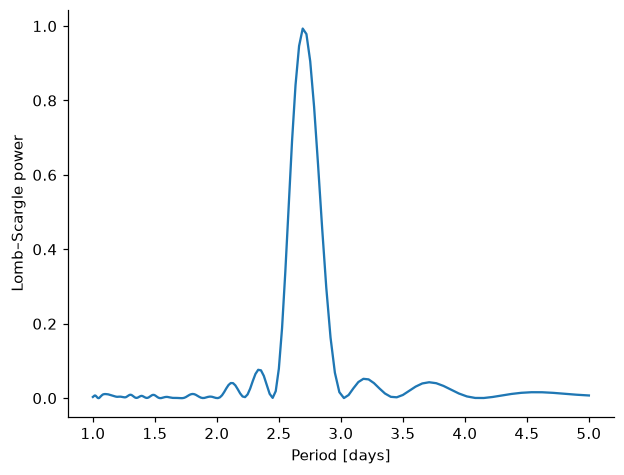

In [2]:
# Generate 350 reproducible, unevenly spaced timestamps across 25 days.
rng = np.random.default_rng(19)
time = np.sort(rng.uniform(0, 25, 350))

# Add Gaussian noise to a cosine signal with a known 2.7-day period.
lc = Nahiku(time, np.cos(2*np.pi*time/2.7)+rng.normal(0, .05, len(time)))

# Search periods from 1 to 5 days using the actual observation timestamps.
period = lc.estimate_period(minimum_period=1, maximum_period=5)
print("Estimated period:", period)

# Display the stored Lomb–Scargle power against period rather than frequency.
fig, ax = plt.subplots()
ax.plot(1/lc.period_result["frequency"], lc.period_result["power"])
ax.set(xlabel="Period [days]", ylabel="Lomb–Scargle power");

# Verify recovery of the known period to within 0.05 day.
assert abs(period-2.7) < .05

## Interpret the result

The recovered period of 2.69 days is close to the injected 2.7 days. False-alarm probabilities assume the periodogram noise model; correlated variability, aliases, and boundary peaks require inspection. An inconclusive result returns `None` by default. Optional `fallback="shoulder"` supplies a heuristic initialization timescale, not a significant periodic detection; inspect `period_result["fallback_used"]`, `"peak_accepted"`, and `"reason"` to distinguish them.

Consult the API reference for parameter and return-value details.